# Bài tập 2 - Hồng Sen

Môn 121036. Người phụ trách: **Hồng Sen**.

Hoàn thành nội bộ: **18/11/2026**. Hạn nộp: **20/11/2026**.

Bộ khung chưa có thuật toán hoặc kết quả thực nghiệm. Đọc `README.md`, đề Bài tập 2 và bảng phân công của nhóm.

## 0. Chuẩn bị môi trường

Cell bên dưới do Codex tạo để import thư viện và xác định đường dẫn, ngoài phần cài đặt thuật toán. Các cell cài đặt được để trống.

**Khai báo AI cho cell chuẩn bị**

- Công cụ: Codex (OpenAI).
- Mục đích: tạo bộ khung thư mục, notebook và đường dẫn dùng chung.
- Prompt nguyên văn:

> giờ bạn tạo cái sườn giúp tôi [https://github.com/NguyenTanHiep07/xla-121036](https://github.com/NguyenTanHiep07/xla-121036) làm tiếp trong này cho dễ nha tạo mấy thư mục mấy cũ ko liên quan á bỏ qua

In [17]:
from pathlib import Path
from functools import partial
import math
import time
import cv2

import numpy as np
import matplotlib.pyplot as plt

# Chuẩn bị đường dẫn, không cài đặt thuật toán.
thu_muc_chay = Path.cwd().resolve()
thu_muc_tim = (
    thu_muc_chay,
    thu_muc_chay / "bai_tap_2",
    thu_muc_chay.parent,
)
BT2_DIR = next(
    (p for p in thu_muc_tim if (p / "bt2_nhom.ipynb").is_file()),
    None,
)
if BT2_DIR is None:
    raise FileNotFoundError(
        "Chọn thư mục chạy là gốc repo, bai_tap_2 hoặc bai_tap_2/lam_viec."
    )
IMAGES_DIR = BT2_DIR.parent / "images"
image_path = IMAGES_DIR / "uneven_lighting.jpg"

print("Bài tập 2:", BT2_DIR)
print("Ảnh dùng chung:", IMAGES_DIR)
print("Đường dẫn ảnh:", image_path)
print("Ảnh tồn tại:", image_path.is_file())

Bài tập 2: C:\Users\Hong sen\Downloads\xla-121036-git\bai_tap_2
Ảnh dùng chung: C:\Users\Hong sen\Downloads\xla-121036-git\images
Đường dẫn ảnh: C:\Users\Hong sen\Downloads\xla-121036-git\images\uneven_lighting.jpg
Ảnh tồn tại: True


## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `region_growing_classic(img, seeds, T, order="stack")`

order: stack hoặc queue. Trả labels int32, -1 cho pixel chưa thuộc vùng nào.

In [2]:
def region_growing_classic(img, seeds, T, order="stack"):
    """
    Region Growing cổ điển.

    Parameters
    ----------
    img : ndarray
        Ảnh xám 2 chiều.
    seeds : iterable
        Danh sách tọa độ (row, col).
    T : float
        Ngưỡng chênh lệch cường độ.
    order : str
        "stack" (LIFO) hoặc "queue" (FIFO).

    Returns
    -------
    labels : ndarray, dtype=int32
        Nhãn vùng; -1 là pixel chưa được gán.
    """
    img = np.asarray(img, dtype=np.float64)

    if img.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều.")

    if not np.isfinite(img).all():
        raise ValueError("img không được chứa NaN hoặc Inf.")

    if not np.isscalar(T) or not np.isfinite(T) or T < 0:
        raise ValueError("T phải là số hữu hạn không âm.")

    if order not in ("stack", "queue"):
        raise ValueError("order chỉ nhận 'stack' hoặc 'queue'.")

    height, width = img.shape
    labels = np.full((height, width), -1, dtype=np.int32)

    seeds = [(int(r), int(c)) for r, c in seeds]

    if len(set(seeds)) != len(seeds):
        raise ValueError("Các seed không được trùng nhau.")

    for r, c in seeds:
        if not (0 <= r < height and 0 <= c < width):
            raise ValueError(f"Seed {(r, c)} nằm ngoài ảnh.")

    # Lân cận 4 hướng.
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for region_id, (sr, sc) in enumerate(seeds):

        # Bỏ qua seed đã thuộc vùng được xử lý trước đó.
        if labels[sr, sc] != -1:
            continue

        labels[sr, sc] = region_id

        frontier = [(sr, sc)]
        head = 0

        region_sum = float(img[sr, sc])
        region_count = 1
        region_mean = region_sum

        while (frontier if order == "stack" else head < len(frontier)):

            if order == "stack":
                r, c = frontier.pop()
            else:
                r, c = frontier[head]
                head += 1

            for dr, dc in neighbors:
                nr, nc = r + dr, c + dc

                if not (0 <= nr < height and 0 <= nc < width):
                    continue

                if labels[nr, nc] != -1:
                    continue

                if abs(float(img[nr, nc]) - region_mean) <= T:
                    labels[nr, nc] = region_id

                    frontier.append((nr, nc))

                    region_sum += float(img[nr, nc])
                    region_count += 1
                    region_mean = region_sum / region_count

    return labels

### `seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3)`

Trả bản đồ tần suất đổi nhãn khi nhiễu vị trí hạt giống, theo định nghĩa đề.

In [7]:
def seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3):
    if n_trials <= 0:
        raise ValueError("n_trials phải lớn hơn 0.")
    if jitter < 0:
        raise ValueError("jitter không được âm.")

    img = np.asarray(img)
    seeds = np.asarray(seeds, dtype=np.int32)

    if img.ndim < 2:
        raise ValueError("Ảnh phải có ít nhất 2 chiều.")
    if seeds.ndim != 2 or seeds.shape[1] != 2 or len(seeds) == 0:
        raise ValueError("seeds phải có dạng danh sách (row, col).")

    height, width = img.shape[:2]

    if np.any(seeds[:, 0] < 0) or np.any(seeds[:, 0] >= height):
        raise ValueError("Seed có tọa độ row ngoài ảnh.")
    if np.any(seeds[:, 1] < 0) or np.any(seeds[:, 1] >= width):
        raise ValueError("Seed có tọa độ col ngoài ảnh.")
    if len(np.unique(seeds, axis=0)) != len(seeds):
        raise ValueError("Các seed ban đầu không được trùng nhau.")

    def get_labels(result):
        if isinstance(result, tuple):
            result = result[0]
        result = np.asarray(result)

        if result.shape != (height, width):
            raise ValueError("segment_fn phải trả về bản đồ nhãn H x W.")

        return result

    baseline = get_labels(segment_fn(img, seeds.tolist()))

    changed_count = np.zeros((height, width), dtype=np.float32)
    rng = np.random.default_rng()

    for trial in range(n_trials):
        perturbed_seeds = []
        used_positions = set()

        for seed in seeds:
            row, col = map(int, seed)
            chosen_seed = None

            for attempt in range(100):
                dr = int(rng.integers(-jitter, jitter + 1))
                dc = int(rng.integers(-jitter, jitter + 1))

                new_row = int(np.clip(row + dr, 0, height - 1))
                new_col = int(np.clip(col + dc, 0, width - 1))

                candidate = (new_row, new_col)

                if candidate not in used_positions:
                    chosen_seed = candidate
                    break

            if chosen_seed is None:
                candidate = (row, col)
                if candidate not in used_positions:
                    chosen_seed = candidate
                else:
                    raise ValueError("Không tạo được các seed riêng biệt.")

            perturbed_seeds.append(chosen_seed)
            used_positions.add(chosen_seed)

        trial_labels = get_labels(
            segment_fn(img, perturbed_seeds)
        )

        changed_count += (trial_labels != baseline)

    sensitivity_map = changed_count / n_trials

    return sensitivity_map.astype(np.float32)

Image shape: (480, 640)
Image dtype: uint8
Intensity range: 0 - 255


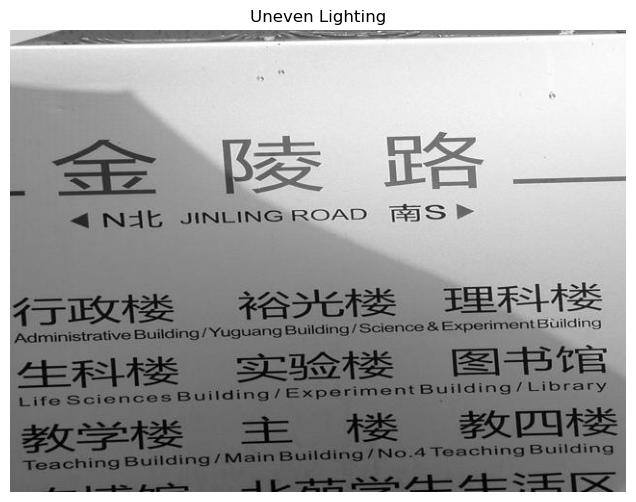

In [11]:
test_img = cv2.imread(
    str(image_path),
    cv2.IMREAD_GRAYSCALE
)

if test_img is None:
    raise FileNotFoundError(str(image_path))

print("Image shape:", test_img.shape)
print("Image dtype:", test_img.dtype)
print("Intensity range:", test_img.min(), "-", test_img.max())

plt.figure(figsize=(8, 6))
plt.imshow(test_img, cmap="gray")
plt.title("Uneven Lighting")
plt.axis("off")
plt.show()

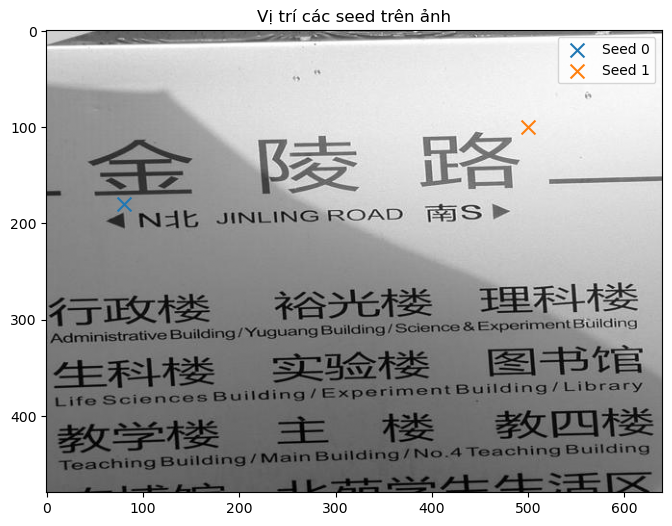

Kích thước ảnh: (480, 640)
Danh sách seed: [(180, 80), (100, 500)]
Cường độ tại các seed: [140, 238]


In [12]:
test_seeds = [
    (180, 80),
    (100, 500)
]

plt.figure(figsize=(9, 6))
plt.imshow(test_img, cmap="gray")

for i, (r, c) in enumerate(test_seeds):
    plt.scatter(c, r, marker="x", s=100, label=f"Seed {i}")

plt.title("Vị trí các seed trên ảnh")
plt.legend()
plt.axis("on")
plt.show()

print("Kích thước ảnh:", test_img.shape)
print("Danh sách seed:", test_seeds)
print(
    "Cường độ tại các seed:",
    [int(test_img[r, c]) for r, c in test_seeds]
)

Kích thước bản đồ nhãn: (480, 640)
Kiểu dữ liệu: int32
Các nhãn vùng: [-1  0  1]
Số pixel chưa được gán: 277184


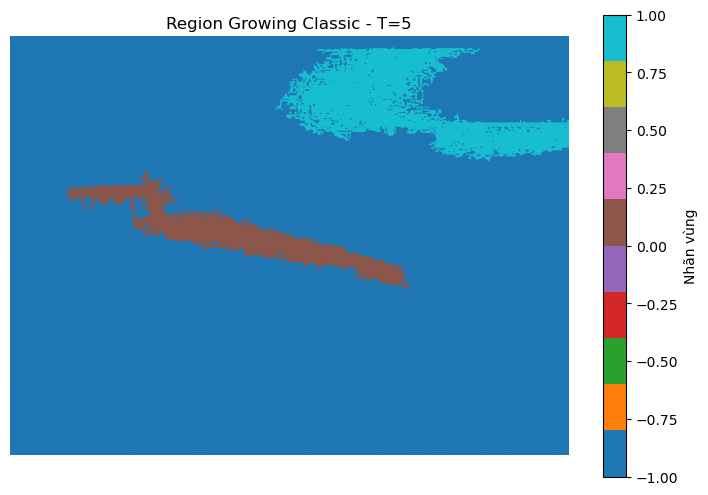

In [13]:
labels = region_growing_classic(
 test_img,
 test_seeds,
 T=5,
 order="stack"
)
print("Kích thước bản đồ nhãn:", labels.shape)
print("Kiểu dữ liệu:", labels.dtype)
print("Các nhãn vùng:", np.unique(labels))
print("Số pixel chưa được gán:", np.sum(labels == -1))
plt.figure(figsize=(9, 6))
plt.imshow(labels, cmap="tab10")
plt.title("Region Growing Classic - T=5")
plt.colorbar(label="Nhãn vùng")
plt.axis("off")
plt.show()

Kích thước ảnh: (480, 640)
Số pixel khác nhau: 39345
Tỷ lệ pixel khác nhau (%): 12.8076171875


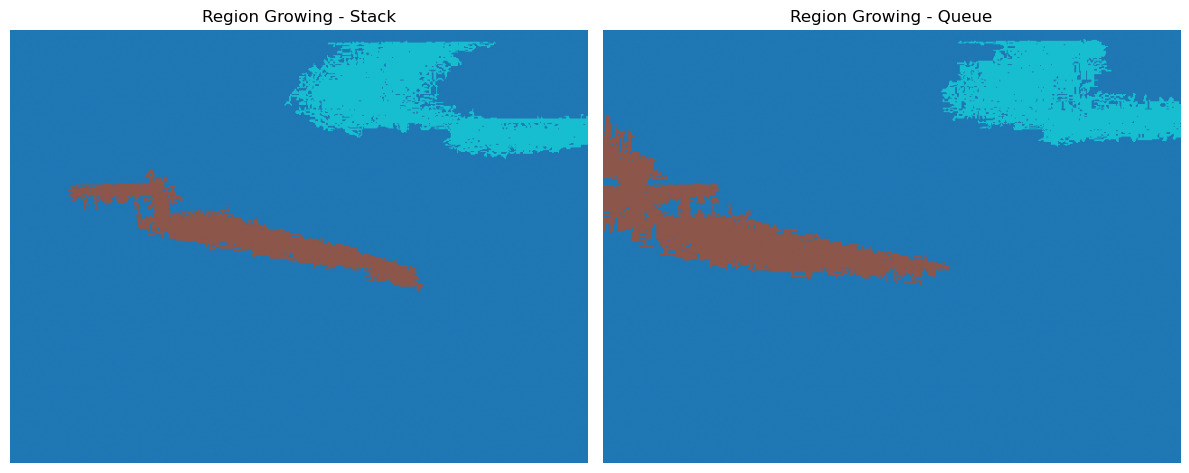

In [14]:
labels_stack = region_growing_classic(
 test_img, test_seeds, T=5, order="stack"
)
labels_queue = region_growing_classic(
 test_img, test_seeds, T=5, order="queue"
)
different_pixels = np.sum(labels_stack != labels_queue)
different_percent = different_pixels / labels_stack.size * 100
print("Kích thước ảnh:", test_img.shape)
print("Số pixel khác nhau:", different_pixels)
print("Tỷ lệ pixel khác nhau (%):", different_percent)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(labels_stack, cmap="tab10")
axes[0].set_title("Region Growing - Stack")
axes[0].axis("off")
axes[1].imshow(labels_queue, cmap="tab10")
axes[1].set_title("Region Growing - Queue")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [15]:
print("=== KIỂM TRA REGION GROWING ===")
print("Stack - shape:", labels_stack.shape)
print("Stack - dtype:", labels_stack.dtype)
print("Queue - shape:", labels_queue.shape)
print("Queue - dtype:", labels_queue.dtype)
print("Stack - số nhãn:", np.unique(labels_stack))
print("Queue - số nhãn:", np.unique(labels_queue))
assert labels_stack.shape == test_img.shape
assert labels_queue.shape == test_img.shape
assert labels_stack.dtype == np.int32
assert labels_queue.dtype == np.int32
print("Kiểm tra Region Growing: PASS")

=== KIỂM TRA REGION GROWING ===
Stack - shape: (480, 640)
Stack - dtype: int32
Queue - shape: (480, 640)
Queue - dtype: int32
Stack - số nhãn: [-1  0  1]
Queue - số nhãn: [-1  0  1]
Kiểm tra Region Growing: PASS


Kích thước: (64, 64)
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 0.75


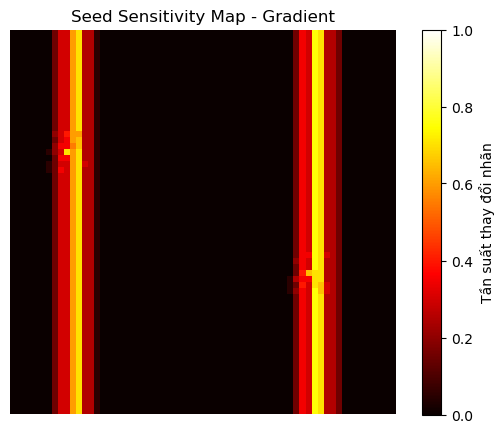

In [18]:
# Tạo ảnh Gradient 64 x 64
gradient_img = np.tile(
 np.linspace(0, 255, 64, dtype=np.uint8),
    (64, 1)
)
gradient_seeds = [(20, 10), (40, 50)]
segment_gradient = partial(
 region_growing_classic,
 T=5,
 order="stack"
)
sensitivity_gradient = seed_sensitivity(
 gradient_img,
 gradient_seeds,
 segment_gradient,
 n_trials=20,
 jitter=3
)
print("Kích thước:", sensitivity_gradient.shape)
print("Giá trị nhỏ nhất:", sensitivity_gradient.min())
print("Giá trị lớn nhất:", sensitivity_gradient.max())
plt.figure(figsize=(7, 5))
plt.imshow(
 sensitivity_gradient,
 cmap="hot",
 vmin=0,
 vmax=1
)
plt.colorbar(label="Tần suất thay đổi nhãn")
plt.title("Seed Sensitivity Map - Gradient")
plt.axis("off")
plt.show()

Kích thước: (480, 640)
Kiểu dữ liệu: float32
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 0.75
Số pixel có thay đổi nhãn: 23271
Kiểm tra Seed Sensitivity: PASS


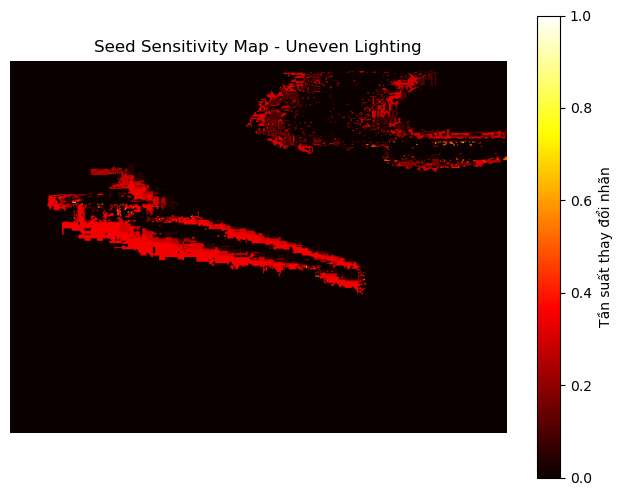

In [19]:
segment_fn = partial(
    region_growing_classic,
    T=5,
    order="stack"
)

sensitivity = seed_sensitivity(
    test_img,
    test_seeds,
    segment_fn,
    n_trials=20,
    jitter=3
)

print("Kích thước:", sensitivity.shape)
print("Kiểu dữ liệu:", sensitivity.dtype)
print("Giá trị nhỏ nhất:", sensitivity.min())
print("Giá trị lớn nhất:", sensitivity.max())
print("Số pixel có thay đổi nhãn:", np.count_nonzero(sensitivity))

assert sensitivity.shape == test_img.shape
assert sensitivity.dtype == np.float32
assert np.isfinite(sensitivity).all()
assert np.all((sensitivity >= 0) & (sensitivity <= 1))

print("Kiểm tra Seed Sensitivity: PASS")

plt.figure(figsize=(8, 6))
plt.imshow(sensitivity, cmap="hot", vmin=0, vmax=1)
plt.colorbar(label="Tần suất thay đổi nhãn")
plt.title("Seed Sensitivity Map - Uneven Lighting")
plt.axis("off")
plt.show()

## Tích hợp với SRG của Hiệp

Thống nhất biểu diễn seeds và ID vùng. Dùng phiên bản SRG đã được duyệt khi kiểm chứng và đo seed_sensitivity; ghi nguồn/commit.

## Kiểm chứng cài đặt

Mã A1-A5 và B1-B5 bên dưới là thứ tự kiểm chứng trong mục 3.7 / 4.5 của đề. Điền dữ liệu kiểm tra, số đo và output thực tế. Các ô mã hiện để trống.

### Kiểm chứng B1 - Phân hoạch đầy đủ

Kiểm tra mọi labels của SRG >= 0. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Kiểm chứng B2 - Số vùng

Kiểm tra số nhãn phân biệt bằng số hạt giống hợp lệ. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Kiểm chứng B3 - Đảo thứ tự hạt giống

So kết quả sau khi thống nhất lại ý nghĩa ID nhãn; ghi quy tắc phá hòa. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Kiểm chứng B4 - Stack, queue và SRG

Cùng ảnh, cùng seeds; báo số pixel khác nhau trong từng cặp. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

## Thí nghiệm - B: Region Growing đối chiếu SRG; độ nhạy hạt giống

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



## Bàn giao cho nhóm trưởng

- [ ] Đúng giao diện hàm và quy ước tọa độ.
- [ ] Restart & Run All chạy được, đã lưu output.
- [ ] Ảnh cần dùng có trong images/ tại gốc repo; dùng IMAGES_DIR để đọc ảnh.
- [ ] Kiểm chứng và thí nghiệm có số đo thực tế.
- [ ] Cell thí nghiệm có dùng AI ghi đúng prompt ngay phía trên.
- [ ] Đã mở Pull Request và ghi nguồn các hàm dùng chung.